In [ ]:
import os, shutil, random, pathlib
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, callbacks
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

TensorFlow version: 2.20.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import os, shutil, random, pathlib
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import layers, callbacks
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
BLOCK_SIZE = 30
preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input

In [ ]:
!pip install -q kagglehub
import kagglehub

path = kagglehub.dataset_download("ismailnasri20/driver-drowsiness-dataset-ddd")
print("Dataset downloaded to:", path)

DATA_DIR = path

Using Colab cache for faster access to the 'driver-drowsiness-dataset-ddd' dataset.
Dataset downloaded to: /kaggle/input/driver-drowsiness-dataset-ddd


In [ ]:
import pathlib
import shutil
import numpy as np
from sklearn.model_selection import GroupShuffleSplit

CLASS_FOLDERS = {"Drowsy": "Drowsy", "Non Drowsy": "Non Drowsy"}

SPLIT_DIR = pathlib.Path("/content/ddd_split")

for split in ["train", "val", "test"]:
    for cls in CLASS_FOLDERS:
        (SPLIT_DIR / split / cls).mkdir(parents=True, exist_ok=True)

dataset_root = pathlib.Path(DATA_DIR)

drowsy_dir = None
non_drowsy_dir = None

for p in dataset_root.rglob("*"):
    if p.is_dir():
        if p.name.lower() == "drowsy":
            drowsy_dir = p
        elif p.name.lower() in ["non drowsy", "non_drowsy", "nondrowsy"]:
            non_drowsy_dir = p

folders = {
    "Drowsy": drowsy_dir,
    "Non Drowsy": non_drowsy_dir
}

BLOCK_SIZE = 30

for cls_label, src_dir in folders.items():

    all_files = sorted([f for f in src_dir.glob("*") if f.is_file()])

    print(f"{cls_label}: {len(all_files)} images found")

    groups = np.array([i // BLOCK_SIZE for i in range(len(all_files))])

    gss1 = GroupShuffleSplit(
        n_splits=1,
        test_size=0.30,
        random_state=SEED
    )

    train_idx, temp_idx = next(gss1.split(all_files, groups=groups))

    temp_files = [all_files[i] for i in temp_idx]
    temp_groups = groups[temp_idx]

    gss2 = GroupShuffleSplit(
        n_splits=1,
        test_size=0.50,
        random_state=SEED
    )

    val_idx, test_idx = next(gss2.split(temp_files, groups=temp_groups))

    train_files = [all_files[i] for i in train_idx]
    val_files = [temp_files[i] for i in val_idx]
    test_files = [temp_files[i] for i in test_idx]

    for f in train_files:
        shutil.copy(f, SPLIT_DIR / "train" / cls_label / f.name)

    for f in val_files:
        shutil.copy(f, SPLIT_DIR / "val" / cls_label / f.name)

    for f in test_files:
        shutil.copy(f, SPLIT_DIR / "test" / cls_label / f.name)

    print(f"Train: {len(train_files)}")
    print(f"Validation: {len(val_files)}")
    print(f"Test: {len(test_files)}")

Drowsy: 22348 images found
Train: 15628
Validation: 3360
Test: 3360
Non Drowsy: 19445 images found
Train: 13595
Validation: 2910
Test: 2940


In [ ]:
test_ds = tf.keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False,
)

print("Classes:", test_ds.class_names)

Found 6300 files belonging to 2 classes.
Classes: ['Drowsy', 'Non Drowsy']


In [ ]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "train", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="binary", shuffle=True, seed=SEED,
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "val", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="binary", shuffle=False,
)
test_ds = tf.keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "test", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="binary", shuffle=False,
)
class_names = train_ds.class_names
print("Class names (0/1 order):", class_names)

Found 29223 files belonging to 2 classes.
Found 6270 files belonging to 2 classes.
Found 6300 files belonging to 2 classes.
Class names (0/1 order): ['Drowsy', 'Non Drowsy']


In [ ]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
], name="data_augmentation")

preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input
AUTOTUNE = tf.data.AUTOTUNE

def prepare(ds, training=False):
    if training:
        ds = ds.map(lambda x, y: (data_augmentation(x), y), num_parallel_calls=AUTOTUNE)
    ds = ds.map(lambda x, y: (preprocess_input(x), y), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

train_ds_p = prepare(train_ds, training=True)
val_ds_p = prepare(val_ds)
test_ds_p = prepare(test_ds)

In [ ]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=IMG_SIZE + (3,), include_top=False, weights="imagenet",
)
base_model.trainable = False

inputs = tf.keras.Input(shape=IMG_SIZE + (3,))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

model = tf.keras.Model(inputs, outputs)
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.Precision(name="precision"), tf.keras.metrics.Recall(name="recall")],
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import tensorflow as tf
model = tf.keras.models.load_model("/content/drive/MyDrive/drowsiness_model_final.keras")
print("Model loaded successfully.")

Mounted at /content/drive
Model loaded successfully.


In [ ]:
early_stop = callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)
checkpoint = callbacks.ModelCheckpoint(
    "/content/drive/MyDrive/best_model_stage1.keras",
    monitor="val_loss", save_best_only=True
)

EPOCHS = 8
history = model.fit(
    train_ds_p, validation_data=val_ds_p, epochs=EPOCHS,
    callbacks=[early_stop, checkpoint],
)

Epoch 1/8
914/914 ━━━━━━━━━━━━━━━━━━━━ 405s 417ms/step - accuracy: 0.9362 - loss: 0.1599 - precision: 0.9346 - recall: 0.9277 - val_accuracy: 0.9880 - val_loss: 0.0412 - val_precision: 0.9961 - val_recall: 0.9780
Epoch 2/8
914/914 ━━━━━━━━━━━━━━━━━━━━ 348s 380ms/step - accuracy: 0.9856 - loss: 0.0447 - precision: 0.9853 - recall: 0.9837 - val_accuracy: 0.9967 - val_loss: 0.0125 - val_precision: 0.9969 - val_recall: 0.9959
Epoch 3/8
914/914 ━━━━━━━━━━━━━━━━━━━━ 382s 381ms/step - accuracy: 0.9912 - loss: 0.0273 - precision: 0.9912 - recall: 0.9899 - val_accuracy: 0.9973 - val_loss: 0.0089 - val_precision: 0.9966 - val_recall: 0.9976
Epoch 4/8
914/914 ━━━━━━━━━━━━━━━━━━━━ 382s 381ms/step - accuracy: 0.9913 - loss: 0.0245 - precision: 0.9914 - recall: 0.9899 - val_accuracy: 0.9978 - val_loss: 0.0092 - val_precision: 0.9976 - val_recall: 0.9976
Epoch 5/8
914/914 ━━━━━━━━━━━━━━━━━━━━ 358s 391ms/step - accuracy: 0.9946 - loss: 0.0161 - precision: 0.9946 - recall: 0.9937 - val_accuracy: 0.9976

In [ ]:
model.save("/content/drive/MyDrive/drowsiness_model_final.keras")
print("Model saved.")

Model saved.


In [ ]:
import os
path = "/content/drive/MyDrive/drowsiness_model_final.keras"
print("File exists:", os.path.exists(path))
print("File size (MB):", os.path.getsize(path) / (1024*1024))

File exists: True
File size (MB): 11.054956436157227


In [ ]:
results = model.evaluate(test_ds_p)
print(dict(zip(model.metrics_names, results)))

197/197 ━━━━━━━━━━━━━━━━━━━━ 25s 90ms/step - accuracy: 0.9976 - loss: 0.0063 - precision: 0.9980 - recall: 0.9969
{'loss': 0.006275899242609739, 'compile_metrics': 0.9976190328598022}


              precision    recall  f1-score   support

      Drowsy       1.00      1.00      1.00      3360
  Non Drowsy       1.00      1.00      1.00      2940

    accuracy                           1.00      6300
   macro avg       1.00      1.00      1.00      6300
weighted avg       1.00      1.00      1.00      6300



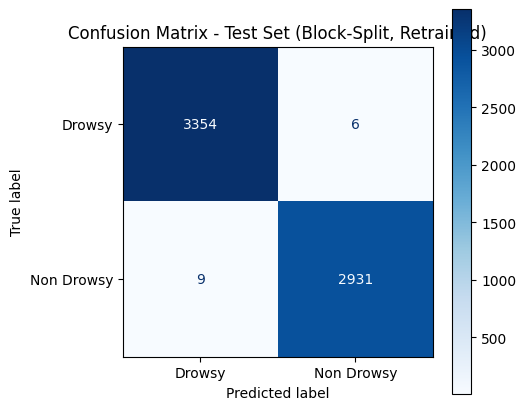

In [ ]:

import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_true, y_pred_prob = [], []
for images, labels in test_ds_p:
    preds = model.predict(images, verbose=0)
    y_pred_prob.extend(preds.flatten())
    y_true.extend(labels.numpy().flatten())

y_true = np.array(y_true)
y_pred_prob = np.array(y_pred_prob)
y_pred = (y_pred_prob >= 0.5).astype(int)

print(classification_report(y_true, y_pred, target_names=class_names))

cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(5, 5))
disp.plot(ax=ax, cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Test Set (Block-Split, Retrained)")
plt.show()

In [ ]:
print('y_true' in dir())
print('y_pred_prob' in dir())

True
True


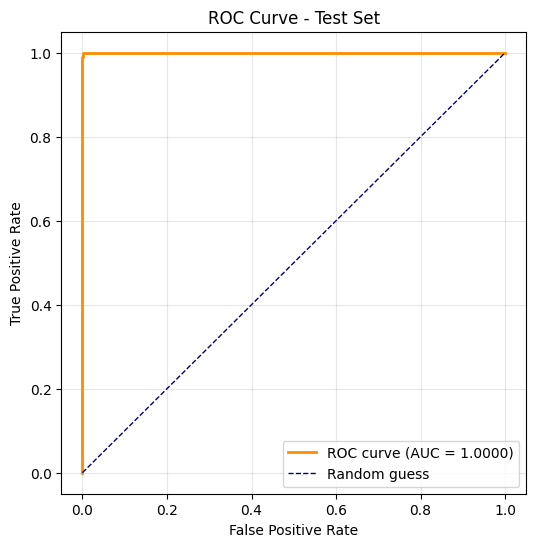

In [ ]:
from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(y_true, y_pred_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=1, linestyle='--', label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Test Set')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()

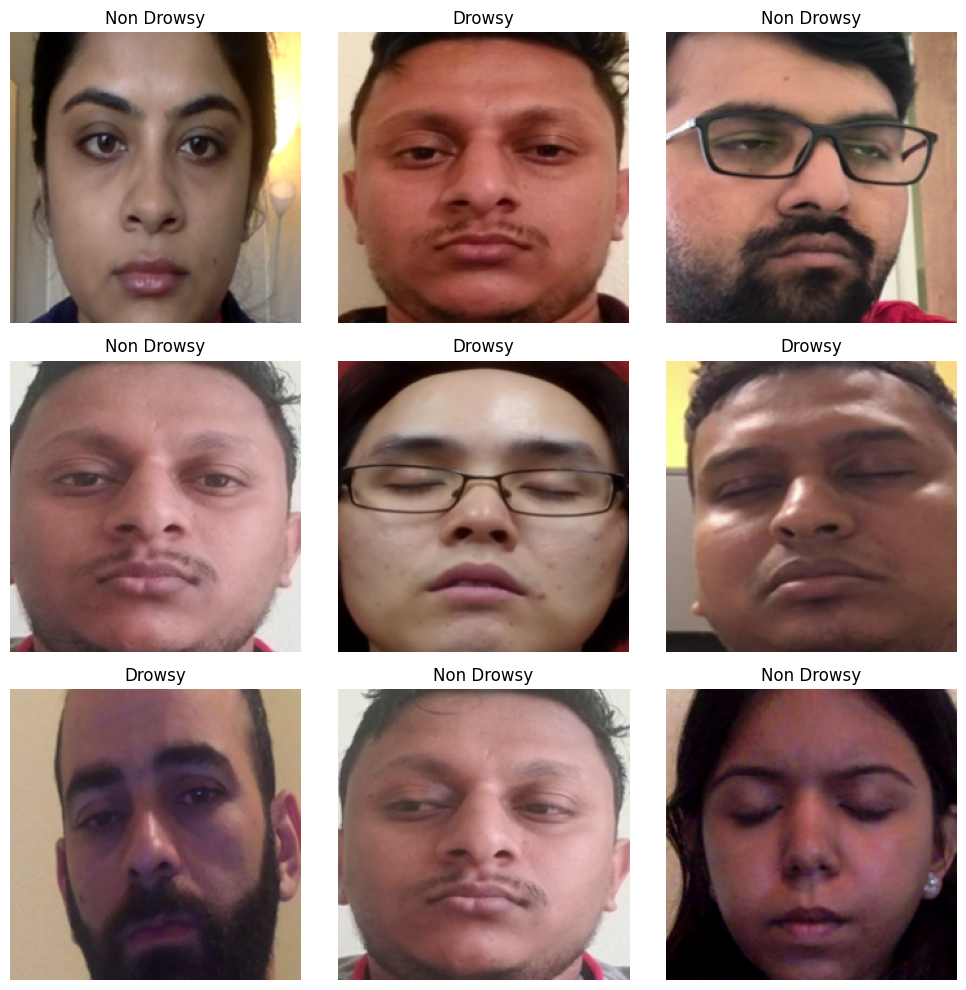

In [ ]:
plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i][0])])
        plt.axis("off")
plt.tight_layout()
plt.show()

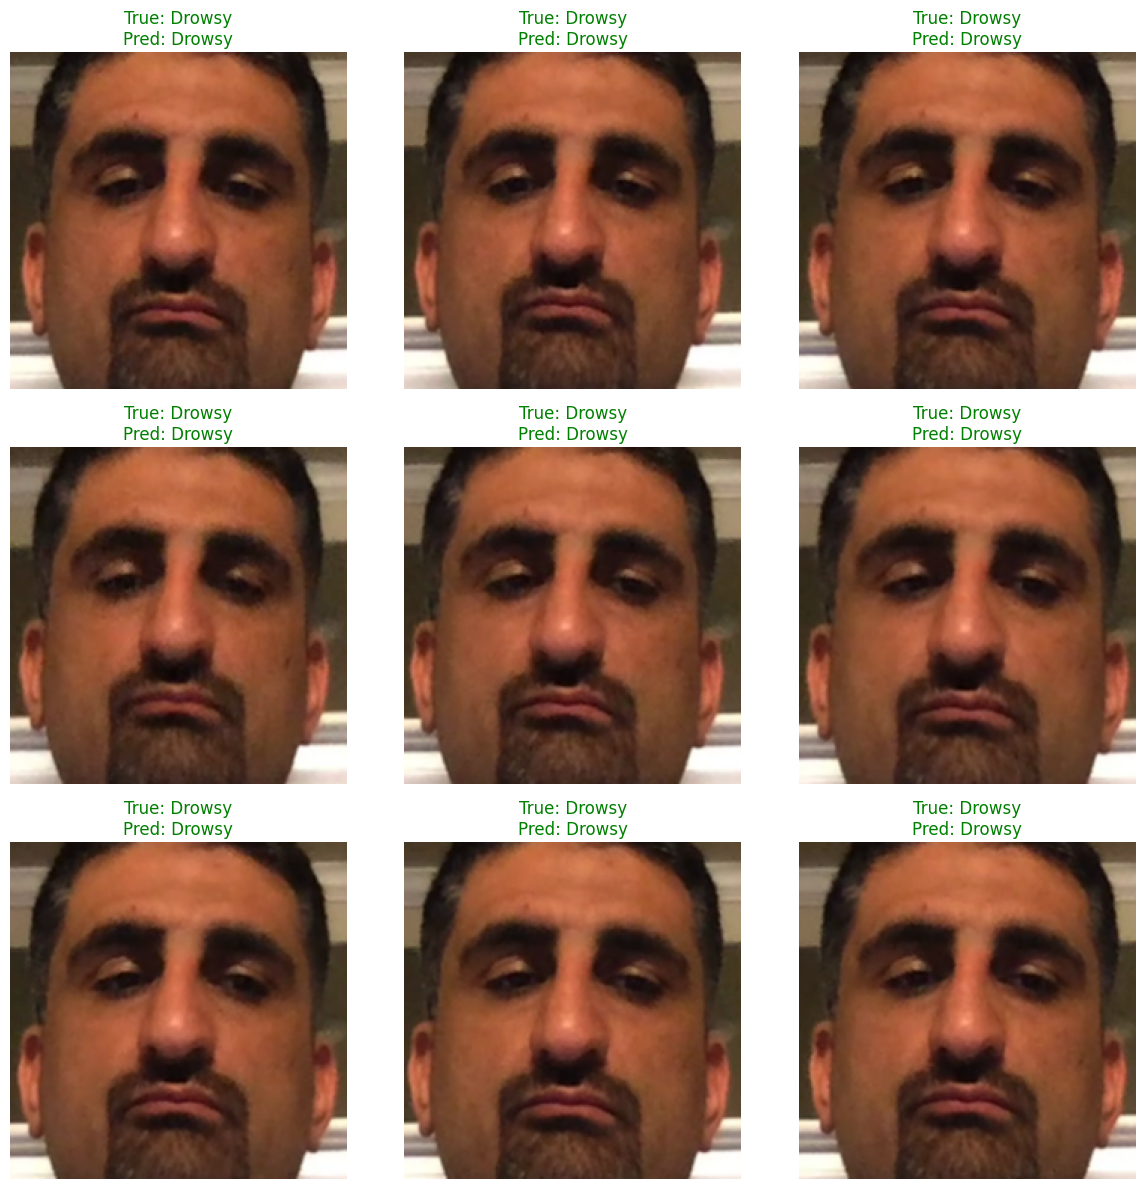

In [ ]:
plt.figure(figsize=(12, 12))
shown = 0
for images, labels in test_ds.take(3):
    preds = model.predict(preprocess_input(tf.cast(images, tf.float32)), verbose=0)
    for i in range(len(images)):
        if shown >= 9:
            break
        ax = plt.subplot(3, 3, shown + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        true_label = class_names[int(labels[i][0])]
        pred_label = class_names[int(preds[i][0] >= 0.5)]
        color = "green" if true_label == pred_label else "red"
        plt.title(f"True: {true_label}\nPred: {pred_label}", color=color)
        plt.axis("off")
        shown += 1
    if shown >= 9:
        break
plt.tight_layout()
plt.show()

In [ ]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode

def take_photo_debug(filename='photo.jpg', quality=0.9):
    js = Javascript('''
        async function takePhoto(quality) {
            alert("Step 1: Starting function");

            const div = document.createElement('div');
            div.style.border = '3px solid red';
            div.style.padding = '10px';

            const capture = document.createElement('button');
            capture.textContent = 'CLICK TO CAPTURE';
            capture.style.fontSize = '24px';
            capture.style.padding = '15px 30px';
            capture.style.backgroundColor = 'yellow';
            capture.style.display = 'block';
            div.appendChild(capture);

            const video = document.createElement('video');
            video.style.width = '400px';
            video.style.border = '3px solid blue';
            video.autoplay = true;
            video.muted = true;
            video.setAttribute('playsinline', true);

            alert("Step 2: Requesting camera stream");
            const stream = await navigator.mediaDevices.getUserMedia({video: true});
            alert("Step 3: Got stream, attaching to video");

            document.body.appendChild(div);
            div.appendChild(video);
            video.srcObject = stream;

            alert("Step 4: Video element attached, waiting for play");
            await video.play();
            alert("Step 5: Video is playing - you should see it now with a blue border");

            google.colab.output.setIframeHeight(600, true);

            await new Promise((resolve) => capture.onclick = resolve);
            alert("Step 6: Capture button clicked");

            const canvas = document.createElement('canvas');
            canvas.width = video.videoWidth;
            canvas.height = video.videoHeight;
            canvas.getContext('2d').drawImage(video, 0, 0);
            stream.getVideoTracks()[0].stop();
            div.remove();
            return canvas.toDataURL('image/jpeg', quality);
        }
        ''')
    display(js)
    data = eval_js('takePhoto({})'.format(quality))
    binary = b64decode(data.split(',')[1])
    with open(filename, 'wb') as f:
        f.write(binary)
    return filename

In [ ]:
filename = take_photo_debug()

<IPython.core.display.Javascript object>

In [ ]:
import cv2
from IPython.display import Audio, display

face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')

def generate_alarm_beep(duration=1.5, freq=880, sample_rate=22050):
    t = np.linspace(0, duration, int(sample_rate * duration), endpoint=False)
    tone = np.sin(2 * np.pi * freq * t)
    envelope = (np.sin(2 * np.pi * 3 * t) > 0).astype(float)
    alarm = tone * envelope
    return alarm, sample_rate

def predict_and_alert(filename):
    img_bgr = cv2.imread(filename)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

    faces = face_cascade.detectMultiScale(gray, scaleFactor=1.05, minNeighbors=3, minSize=(80, 80))
    if len(faces) == 0:
        print("No face detected - try retaking the photo with better lighting/framing.")
        return

    x, y, w, h = max(faces, key=lambda f: f[2] * f[3])
    face_crop = img_rgb[y:y+h, x:x+w]

    face_resized = cv2.resize(face_crop, IMG_SIZE)
    face_array = face_resized.astype("float32")
    face_array = preprocess_input(face_array)
    face_batch = np.expand_dims(face_array, axis=0)

    pred = model.predict(face_batch, verbose=0)
    pred_label = class_names[int(pred[0][0] >= 0.5)]
    confidence = pred[0][0] if pred_label == class_names[1] else 1 - pred[0][0]

    plt.figure(figsize=(5, 5))
    plt.imshow(face_crop)
    title_color = "red" if pred_label == "Drowsy" else "green"
    plt.title(f"Prediction: {pred_label} ({confidence:.2%} confidence)", color=title_color)
    plt.axis("off")
    plt.show()

    if pred_label == "Drowsy":
        print("DROWSINESS DETECTED — ALARM TRIGGERED ")
        alarm, sr = generate_alarm_beep()
        display(Audio(alarm, rate=sr, autoplay=True))
    else:
        print("Driver appears alert.")

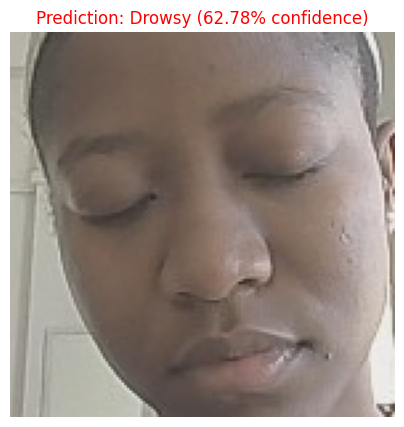

DROWSINESS DETECTED — ALARM TRIGGERED 


In [ ]:
predict_and_alert(filename)